**Library installation**

In [ ]:
!pip install pytorch_lightning
!pip install noise

**Thermal Solver**

tensor(345.2900, device='cuda:0', dtype=torch.float64) tensor(345.2900, device='cuda:0', dtype=torch.float64) tensor(345.2900, device='cuda:0', dtype=torch.float64)
max|Td-Tg|= 0.00015965855209287838


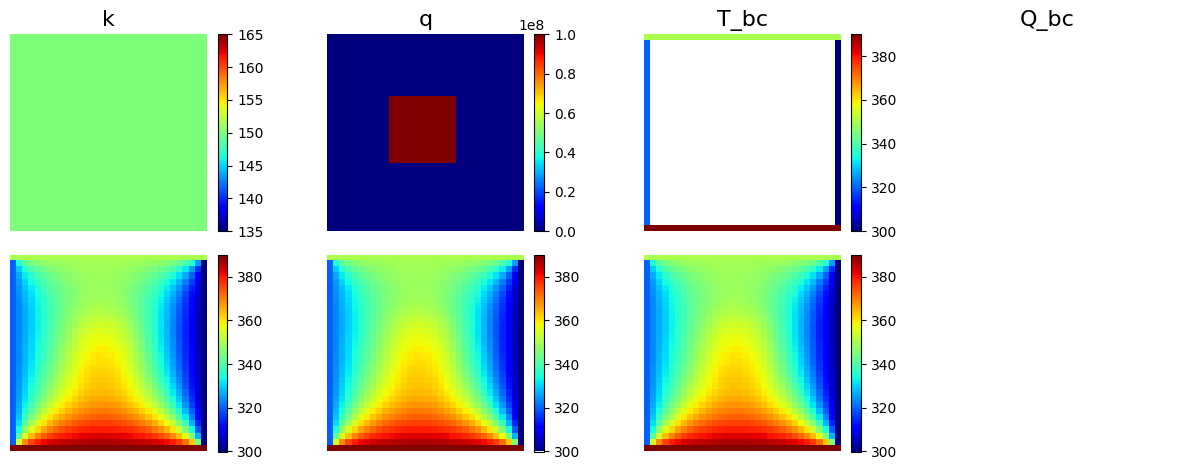

In [ ]:
import numpy as np
import torch
from typing import Literal, Optional


def check_inputs(k, q, T_bc, dm, nm, Q_bc, dx, dy, mode="cg"):
    # dtype/device 통일 (CG는 float64 강제 권장)
    dtype = torch.float64 if mode == "cg" else k.dtype
    dev   = k.device
    toD   = lambda t: t.to(device=dev, dtype=dtype)

    k, q, T_bc, Q_bc = map(toD, (k, q, T_bc, Q_bc))
    dm, nm = dm.to(dev), nm.to(dev)

    def info(name, t):
        print(f"{name:10s} shape={tuple(t.shape)} dtype={t.dtype} "
              f"finite={bool(torch.isfinite(t).all())} "
              f"min={t.min().item():.3e} max={t.max().item():.3e}")

    info("k", k); info("q", q); info("T_bc", T_bc); info("Q_bc", Q_bc)
    print(f"dm True={dm.sum().item()}, nm True={nm.sum().item()}, overlap={(dm & nm).any().item()}")
    # 마스크 유효성
    assert not (dm & nm).any(), "Dirichlet와 Neumann이 겹침(금지)."
    H, W = k.shape[-2:]
    boundary = torch.zeros_like(dm)
    boundary[..., 0, :] = boundary[..., -1, :] = True
    boundary[..., :, 0] = boundary[..., :, -1] = True
    assert bool((nm & (~boundary)).any() == False), "Neumann은 외곽에서만 허용."
    # k 유효성
    kmin = k.min().item()
    assert kmin > 0, f"k에 0/음수 존재: min={kmin}"

    # 예상 스케일 (크면 FP32 금지)
    L = max((H-1)*dx, (W-1)*dy)
    k0 = torch.median(k.flatten()).item()
    q0 = torch.max(torch.abs(q)).item()
    T_scale = q0 * (L**2) / max(k0, 1e-30)
    print(f"Est. T scale ~ {T_scale:.3e}  (FP64 권장: {T_scale>1e5})")


def _harmonic_mean(a, b, eps=1e-12):
    return 2 * a * b / (a + b + eps)


class Heat2DSolver:
    def __init__(
        self,
        dx: float = 1.0,
        dy: float = 1.0,
        mode: Literal["direct", "cg"] = "direct",
        max_iter: int = 10000,
        tol: float = 1e-6,
        reg: float = 1e-8,
        device: Optional[str] = None,
        dtype=torch.float64,
    ):
        self.dx, self.dy = dx, dy
        self.mode, self.max_iter, self.tol = mode, max_iter, tol
        self.reg = reg
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        self.dtype = dtype

    def solve(
        self,
        k: torch.Tensor,
        q: torch.Tensor,
        T_bc: torch.Tensor,
        dirichlet_mask: torch.Tensor,
        neumann_mask: torch.Tensor,
        Q_bc: Optional[torch.Tensor] = None,
    ) -> torch.Tensor:
        """
        k, q, T_bc           : (B, H, W)
        dirichlet_mask       : (B, H, W)  True = Dirichlet node
        neumann_mask         : (B, H, W)  True = Neumann node
        Q_bc                 : (B, H, W)  Neumann flux (optional)
        returns T            : (B, H, W)
        """
        dtype = self.dtype
        device = self.device
        k = k.to(device=device, dtype=dtype)
        q = q.to(device=device, dtype=dtype)
        T_bc = T_bc.to(device=device, dtype=dtype)
        Q_bc = (Q_bc if Q_bc is not None else torch.zeros_like(q)).to(device=device, dtype=dtype)
        dm, nm = dirichlet_mask.to(device), neumann_mask.to(device)

        # k, q, T_bc = [t.to(device).to(torch.float64) for t in (k, q, T_bc)]
        # Q_bc = Q_bc.to(device) if Q_bc is not None else torch.zeros_like(q).to(torch.float64)

        if self.mode == "direct":
            return self._solve_direct(k, q, T_bc, dm, nm, Q_bc)
        elif self.mode == "cg":
            # check_inputs(k, q, T_bc, dm, nm, Q_bc, self.dx, self.dy, mode=self.mode)
            return self._solve_cg(k, q, T_bc, dm, nm, Q_bc)
        else:
            raise ValueError("mode must be 'direct' or 'cg'")

    def _solve_direct(self, k, q, T_bc, dm, nm, Q_bc):
        B, H, W = k.shape
        N = H * W
        dx2, dy2 = self.dx**2, self.dy**2

        # precompute face conductivities
        ke = torch.zeros_like(k); kw = torch.zeros_like(k)
        kn = torch.zeros_like(k); ks = torch.zeros_like(k)
        hm = _harmonic_mean
        ke[:, :, :-1] = hm(k[:, :, :-1], k[:, :, 1:])
        kw[:, :, 1:]  = ke[:, :, :-1]
        kn[:, 1:, :]  = hm(k[:, 1:, :], k[:, :-1, :])
        ks[:, :-1, :] = kn[:, 1:, :]

        A = torch.zeros(B, N, N, device=k.device, dtype=k.dtype)
        b = torch.zeros(B, N,      device=k.device, dtype=k.dtype)

        for bidx in range(B):
            # volumetric source
            b[bidx] = -q[bidx].reshape(N)

            # fill interior stencil
            for i in range(H):
                for j in range(W):
                    idx = i * W + j
                    if dm[bidx, i, j] or nm[bidx, i, j]:
                        continue
                    ce = ke[bidx, i, j] / dx2
                    cw = kw[bidx, i, j] / dx2
                    cn = kn[bidx, i, j] / dy2
                    cs = ks[bidx, i, j] / dy2
                    A[bidx, idx, idx] = -(ce + cw + cn + cs)
                    if j+1 < W: A[bidx, idx, idx+1] =  ce
                    if j-1 >=0: A[bidx, idx, idx-1] =  cw
                    if i+1 < H: A[bidx, idx, idx+W] =  cs
                    if i-1 >=0: A[bidx, idx, idx-W] =  cn

            # Dirichlet rows
            flat_Tbc = T_bc[bidx].reshape(N)
            for idx in (dm[bidx].flatten() == True).nonzero(as_tuple=False).view(-1):
                A[bidx, idx, :] = 0
                A[bidx, idx, idx] = 1
                b[bidx, idx]      = flat_Tbc[idx]

            # Neumann rows
            flat_Qbc = Q_bc[bidx]
            for i in range(H):
                for j in range(W):
                    if not nm[bidx, i, j]:
                        continue
                    idx = i * W + j
                    # identify side & neighbor
                    if j == 0:
                        neigh = idx + 1; coeff = ke[bidx, i, j] / self.dx
                    elif j == W-1:
                        neigh = idx - 1; coeff = kw[bidx, i, j] / self.dx
                    elif i == 0:
                        neigh = idx + W; coeff = ks[bidx, i, j] / self.dy
                    else:  # i == H-1
                        neigh = idx - W; coeff = kn[bidx, i, j] / self.dy

                    A[bidx, idx, :] = 0
                    A[bidx, idx, idx]   = -coeff
                    A[bidx, idx, neigh] =  coeff
                    b[bidx, idx]        = flat_Qbc[i, j]

        # small regularization for invertibility on interior
        if self.reg > 0:
            eye = torch.eye(N, device=k.device, dtype=k.dtype).unsqueeze(0)
            interior = ~(dm|nm).reshape(B, N)
            A = A + eye * (self.reg * interior.unsqueeze(-1).to(k.dtype))

        T_vec = torch.linalg.solve(A, b)  # (B, N)
        return T_vec.view(B, H, W)


    def _solve_cg(self, k, q, T_bc, dm, nm, Q_bc):
        B, H, W = k.shape
        dx2, dy2 = self.dx**2, self.dy**2
        hm = _harmonic_mean

        # precompute face conductivities
        ke = torch.zeros_like(k); kw = torch.zeros_like(k)
        kn = torch.zeros_like(k); ks = torch.zeros_like(k)
        ke[:, :, :-1] = hm(k[:, :, :-1], k[:, :, 1:]); kw[:, :, 1:] = ke[:, :, :-1]
        kn[:, 1:, :]  = hm(k[:, 1:, :], k[:, :-1, :]); ks[:, :-1, :] = kn[:, 1:, :]

        def A_times(X):
            lap = (
                (ke * torch.roll(X, -1, 2) + kw * torch.roll(X, 1, 2)) / dx2 +
                (kn * torch.roll(X, 1, 1) + ks * torch.roll(X, -1, 1)) / dy2 -
                ((ke + kw) / dx2 + (kn + ks) / dy2) * X
            )
            # Dirichlet: identity rows
            lap[dm] = X[dm]

            # Neumann: finite-difference flux rows
            for bidx in range(B):
                for i in range(H):
                    for j in range(W):
                        if not nm[bidx, i, j]:
                            continue
                        idx = i * W + j
                        if j == 0:
                            neigh = (bidx, i, j+1); coeff = ke[bidx, i, j]/self.dx
                        elif j == W-1:
                            neigh = (bidx, i, j-1); coeff = kw[bidx, i, j]/self.dx
                        elif i == 0:
                            neigh = (bidx, i+1, j); coeff = ks[bidx, i, j]/self.dy
                        else:
                            neigh = (bidx, i-1, j); coeff = kn[bidx, i, j]/self.dy

                        # lap = A_times(X) = A·X
                        lap[bidx, i, j] = -coeff * X[bidx, i, j] + coeff * X[neigh]

            return lap

        # RHS
        X = T_bc.clone()
        b = -q.clone()
        b[dm] = T_bc[dm]
        b[nm] = Q_bc[nm]

        r = b - A_times(X)
        p = r.clone()
        rs = (r * r).flatten(1).sum(1, keepdim=True)

        for _ in range(self.max_iter):
            Ap = A_times(p)
            alpha = rs / (p * Ap).flatten(1).sum(1, keepdim=True)
            X = X + alpha.view(B, 1, 1) * p
            r = r - alpha.view(B, 1, 1) * Ap
            rs_new = (r * r).flatten(1).sum(1, keepdim=True)
            if (rs_new.sqrt() < self.tol).all():
                break
            p = r + (rs_new / rs).view(B, 1, 1) * p
            rs = rs_new
        return X


def solve(inp: torch.Tensor, dx: float = 1e-3, dy: float = 1e-3, idx: int = 0):
    """
    input: (B, ch, H, W)
      ch=2 -> k
      ch=3 -> Dirichlet BC temp T_bc
      ch=4 -> volumetric source q
    """
    B, ch, H, W = inp.shape
    k    = inp[:, 2, :, :]
    T_bc = inp[:, 3, :, :]
    q    = inp[:, 4, :, :]

    dirichlet_mask = torch.ones((B, H, W), dtype=torch.bool, device=inp.device)
    dirichlet_mask[:, 1:-1, 1:-1]= False

    neumann_mask = torch.zeros_like(dirichlet_mask)
    Q_bc = torch.zeros_like(q)

    solver_d = Heat2DSolver(dx, dy, mode="direct")

    T_direct = solver_d.solve(k, q, T_bc, dirichlet_mask, neumann_mask, Q_bc)
    return T_direct


class ThermalFEMSolver:
    def solve(self, k, T_bc, q, dx: float = 1.0, dy: float = 1.0):
        H, W = k.shape
        dirichlet_mask = torch.ones((1, H, W), dtype=torch.bool, device=k.device)
        dirichlet_mask[:, 1:-1, 1:-1] = False
        neumann_mask = torch.zeros_like(dirichlet_mask)
        Q_bc = torch.zeros_like(q)
        solver = Heat2DSolver(dx, dy)
        T_direct = solver.solve(k.unsqueeze(0), q.unsqueeze(0), T_bc.unsqueeze(0), dirichlet_mask, neumann_mask, Q_bc)
        return T_direct

    def solve_batch(self, sds, dx: float = 1e-3, dy: float = 1e-3):
        batch_inputs = []
        for sd in sds:
            inputs = torch.stack([sd.k_in, sd.T_in, sd.q_in])
            batch_inputs.append(inputs)
        batch_inputs = torch.stack(batch_inputs)

        B, ch, H, W = batch_inputs.shape
        k    = batch_inputs[:, 0]
        T_bc = batch_inputs[:, 1]
        q    = batch_inputs[:, 2]

        dirichlet_mask = torch.ones((B, H, W), dtype=torch.bool, device=batch_inputs.device)
        dirichlet_mask[:, 1:-1, 1:-1]= False

        neumann_mask = torch.zeros_like(dirichlet_mask)
        Q_bc = torch.zeros_like(q)

        solver_d = Heat2DSolver(dx, dy, mode="direct")
        T_direct = solver_d.solve(k, q, T_bc, dirichlet_mask, neumann_mask, Q_bc)
        # print(batch_inputs.device, solver_d.device)
        self.update_sds(sds, T_direct)

    def update_sds(self, sds, t_out):
        for i, sd in enumerate(sds):
            sd.T_out = t_out[i].clone()


def make_dummy_inputs(B, H, W, device=None):
    dev = torch.device(device if device is not None else ("cuda" if torch.cuda.is_available() else "cpu"))
    shape = (B, H, W)
    k = torch.ones(shape, dtype=torch.double, device=dev)
    q = torch.zeros(shape, dtype=torch.double, device=dev)
    T_bc = torch.zeros(shape, dtype=torch.double, device=dev)
    dm = torch.ones(shape, dtype=torch.bool, device=dev)
    dm[:, 1:-1, 1:-1] = False
    nm = torch.zeros(shape, dtype=torch.bool, device=dev)
    Q_bc = torch.zeros(shape, dtype=torch.double, device=dev)
    return {
        "k": k,
        "q": q,
        "T_bc": T_bc,
        "dirichlet_mask": dm,
        "neumann_mask": nm,
        "Q_bc": Q_bc
    }


def plot_data(named_array_grid, origin='upper', save_path=None,
              same_clim_row=False,        # 행별 vmin/vmax 통일
              cmap='jet',
              titles_top_only=True,       # 맨 윗줄만 제목
              title_size=16,              # 제목 폰트 크기
              fig_scale=1.2,              # 전체 스케일
              cbar_ticks=True):           # 컬러바 틱 표시 여부
    import numpy as np
    import matplotlib.pyplot as plt

    rows = len(named_array_grid)
    cols = max(len(row) for row in named_array_grid)

    fig, axes = plt.subplots(rows, cols,
                             figsize=(2.6 * cols * fig_scale, 2.0 * rows * fig_scale))

    if rows == 1: axes = np.expand_dims(axes, 0)
    if cols == 1: axes = np.expand_dims(axes, 1)
    axes = np.array(axes)

    # --- row별 vmin/vmax 계산 ---
    vlims_row = [None]*rows

    if same_clim_row:
        for i in range(rows):
            vmins, vmaxs = [], []
            for item in named_array_grid[i]:
                if not item or item[1] is None or item[0] == "": continue
                a = item[1].cpu().numpy() if hasattr(item[1], "cpu") else np.array(item[1])
                a = a[np.isfinite(a)]
                if a.size:
                    vmins.append(np.min(a)); vmaxs.append(np.max(a))
            if vmins:
                vlims_row[i] = (float(min(vmins)), float(max(vmaxs)))

    for i in range(rows):
        for j in range(cols):
            ax = axes[i, j]
            try:
                item = named_array_grid[i][j]
                if not item or item[1] is None or item[0] == "":
                    ax.axis('off'); continue

                name, arr = item

                if hasattr(arr, "cpu"): arr = arr.cpu()
                arr = np.array(arr)

                vmin = vmax = None
                if same_clim_row and vlims_row[i] is not None:
                    vmin, vmax = vlims_row[i]

                im = ax.imshow(arr, origin=origin, cmap=cmap, vmin=vmin, vmax=vmax)

                # 제목: 맨 윗줄만 크게/굵게
                if (not titles_top_only) or (i == 0):
                    ax.set_title(name, fontsize=title_size)
                ax.axis('off')

                if not np.isnan(arr).all():
                    cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
                    if not cbar_ticks:
                        cb.set_ticks([]); cb.ax.tick_params(length=0, labelsize=0)

            except Exception:
                ax.axis('off')

    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()

def make_input(B=1, H=32, W=32):
    k = torch.ones(B, H, W) * 150.0  # 예시: 균일 k
    q = torch.zeros(B, H, W)  # 예시: 열원 없음

    # ─── 가운데 1/3×1/3 영역에 발열 넣기 ─────────────────────────
    h0, h1 = H // 3, 2 * H // 3              # 행 범위
    w0, w1 = W // 3, 2 * W // 3              # 열 범위
    q[:, h0:h1, w0:w1] = 1e8 # 1.0e14               # 예: 10⁸ W m⁻³

    # ----------------- 경계 온도 텐서 -----------------
    T_bc = torch.zeros(B, H, W)
    T_bc[:, :, 0] = 320.0
    T_bc[:, :, -1] = 300.0
    T_bc[:, 0, :] = 350.0
    T_bc[:, -1, :] = 390.0

    # ----------------- 마스크 텐서 -----------------
    dirichlet_mask = torch.full((B, H, W), True, dtype=torch.bool)
    dirichlet_mask[:, 1:-1, 1:-1] = False
    neumann_mask = torch.full((B, H, W), False, dtype=torch.bool)
    Q_bc = torch.full((B, H, W), 0, dtype=torch.float32)
    return k, q, T_bc, dirichlet_mask, neumann_mask, Q_bc


def run_demo():
    #from pdeflow.solver.direct_solver_gpu import Heat2DSolver
    dx = dy = 1e-3
    inputs = make_input()
    Td = Heat2DSolver(dx,dy,"direct",dtype=torch.float64).solve(*inputs)
    Tg = Heat2DSolver(dx, dy, "cg", dtype=torch.float64, max_iter=1000, tol=1e-8).solve(*inputs)
    Tf = Heat2DSolver(dx, dy, "direct", dtype=torch.float64).solve(*inputs)

    print(Td.mean(), Tg.mean(), Tf.mean())
    print("max|Td-Tg|=", (Td-Tg).abs().max().item())

    k, q, T_bc, dirichlet_mask, neumann_mask, Q_bc = make_input()
    i = 0
    plot_data([
        [("k", k[i]),
         ("q", q[i]),
         ("T_bc", np.where(dirichlet_mask[0], T_bc[i], np.nan)),
         ("Q_bc", np.where(neumann_mask[0], Q_bc[i], np.nan)),],
        [("Td", Td[i]),
        ("Tcg", Tg[i]),
        ("Tpcg", Tf[i]),
        None,]
    ])


if __name__=="__main__":
    run_demo()


In [ ]:
from typing import Dict, Any

def solve_pde(problem: Dict[str, Any]):
    # 최소 검증(필요시 core.check_problem 사용 가능)
    for k in ('k','q','T_bc','dirichlet_mask','neumann_mask','dx','dy','reg'):
        if k not in problem:
            raise KeyError(f"Problem missing key: {k}")

    solver = Heat2DSolver(dx=problem['dx'], dy=problem['dy'], reg=problem['reg'], device='cpu')
    return solver.solve(
        k=problem['k'], q=problem['q'],
        T_bc=problem['T_bc'],
        dirichlet_mask=problem['dirichlet_mask'],
        neumann_mask=problem['neumann_mask'],
        Q_bc=problem.get('Q_bc', None),
    )


**Data generation**

In [ ]:
import random
from typing import Tuple, Dict, List, Any, Optional
import numpy as np
import torch
from noise import pnoise2

Tensor = torch.Tensor
Problem = Dict[str, Any]  # 표준 스키마: k,q,T_bc,(masks), dx,dy,reg, Q_bc


def to_tensor(x, dtype=torch.float32, device=None) -> Tensor:
    if isinstance(x, torch.Tensor):
        return x.to(dtype=dtype, device=device) if (dtype or device) else x
    return torch.tensor(x, dtype=dtype, device=device)

def generate_perlin_terrain(B=1, H=64, W=64, scale=10.0, k_scale=150.0, seed: Optional[int]=0):
    if seed is not None:
        np.random.seed(seed)
    noise_fn = np.vectorize(lambda y, x, b: pnoise2(y / scale, x / scale, base=b), otypes=[np.float32])
    terrain = np.stack([noise_fn(*np.indices((H, W)), (seed or 0) + b) for b in range(B)])  # (B,H,W)
    terrain -= terrain.min() + 1e-3
    terrain /= terrain.max()
    terrain *= k_scale
    return torch.from_numpy(terrain.astype(np.float32))

def make_input(B=1, H=32, W=32, dx=1e-3, dy=1e-3, reg=1e-8,
               seed: Optional[int]=None, T_range=(0.0, 10.0), q_amp_range=(1e6, 2e7)) -> Dict[str, Any]:
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)

    k = generate_perlin_terrain(B=B, H=H, W=W, scale=6.0, k_scale=300.0, seed=seed)
    k = k - k.min() + 1.0
    q = torch.zeros(B, H, W, dtype=torch.float32)
    h0, h1 = H // 3, 2 * H // 3
    w0, w1 = W // 3, 2 * W // 3

    T_bc = torch.zeros(B, H, W, dtype=torch.float32)
    for b in range(B):
        amp = random.uniform(*q_amp_range)
        q[b, h0:h1, w0:w1] = amp
        T_bc[b, :,  0] = random.uniform(*T_range)
        T_bc[b, :, -1] = random.uniform(*T_range)
        T_bc[b,  0, :] = random.uniform(*T_range)
        T_bc[b, -1, :] = random.uniform(*T_range)

    dm = torch.ones(B, H, W, dtype=torch.bool)
    dm[:, 1:-1, 1:-1] = False
    nm = torch.zeros_like(dm)

    params = {
        'dx': float(dx), 'dy': float(dy), 'reg': float(reg),
        'k': k, 'q': q, 'T_bc': T_bc,
        'dirichlet_mask': dm, 'neumann_mask': nm, 'Q_bc': None
    }
    return params

def mask_T_bc_for_plot(d: Dict[str, Any]):
    # core.mask_T_bc_for_plot를 그대로 써도 되지만, 백워드 컴패티빌리티용 thin wrapper
    from .core import mask_T_bc_for_plot as _mask
    return _mask(d)



def build_input_tensor(sample: Dict[str, Any],
                       use_masks: bool = True,
                       broadcast_dxdy: bool = True,
                       log_kqt: bool = True) -> Tuple[torch.Tensor, torch.Tensor]:
    C = []
    k = to_tensor(sample['k'][0])
    q = to_tensor(sample['q'][0])
    T = to_tensor(sample['T_bc'][0])
    if log_kqt:
        k = torch.log(k + 1e-4); q = torch.log(q + 1e-4); T = torch.log(T + 1e-4)
    C += [k, q, T]

    if use_masks:
        if 'dirichlet_mask' in sample: C.append(to_tensor(sample['dirichlet_mask'][0], dtype=torch.float32))
        if 'neumann_mask'   in sample: C.append(to_tensor(sample['neumann_mask'][0],   dtype=torch.float32))

    H, W = C[0].shape
    if broadcast_dxdy:
        dx = to_tensor(sample['dx']).expand(H, W)
        dy = to_tensor(sample['dy']).expand(H, W)
        C += [dx, dy]

    x = torch.stack(C, dim=0)   # [C,H,W]
    y = solve_pde(sample)       # [1,H,W]
    return x, y


**Model Implementation**

In [ ]:
import os
from pathlib import Path
from typing import Dict, Any, Tuple

import pytorch_lightning as pl
import torch
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset, random_split

class _GNAct(nn.Module):
    def __init__(self, c):
        super().__init__(); self.gn = nn.GroupNorm(max(1, c // 8), c); self.act = nn.SiLU(inplace=True)
    def forward(self, x): return self.act(self.gn(x))

class _DoubleConv(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False), _GNAct(cout),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), _GNAct(cout),
        )
    def forward(self, x): return self.net(x)

class _Down(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(cin, cout, 3, stride=2, padding=1, bias=False),
            _GNAct(cout),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False),
            _GNAct(cout),
        )
    def forward(self, x): return self.net(x)

class _Up(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.up = nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False)
        self.conv = _DoubleConv(cin, cout)
    def forward(self, x, skip):
        x = self.up(x)
        if x.shape[-2:] != skip.shape[-2:]:
            x = nn.functional.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
        x = torch.cat([x, skip], dim=1)
        return self.conv(x)

class UNetSmall(nn.Module):
    def __init__(self, in_ch, base=32, out_ch=1, img_size=None):
        super().__init__()
        self.enc1 = _DoubleConv(in_ch, base)
        self.enc2 = _Down(base, base*2)
        self.enc3 = _Down(base*2, base*4)
        self.bott = _Down(base*4, base*8)
        self.up3  = _Up(base*8 + base*4, base*4)
        self.up2  = _Up(base*4 + base*2, base*2)
        self.up1  = _Up(base*2 + base,   base)
        self.head = nn.Conv2d(base, out_ch, 1)

        self.apply(self._init)

    @staticmethod
    def _init(m):
        if isinstance(m, nn.Conv2d):
            nn.init.kaiming_normal_(m.weight, nonlinearity="relu")

    def forward(self, x):
        s1 = self.enc1(x)
        s2 = self.enc2(s1)
        s3 = self.enc3(s2)
        b  = self.bott(s3)
        x  = self.up3(b, s3)
        x  = self.up2(x, s2)
        x  = self.up1(x, s1)
        return self.head(x)


class TinyCNN(nn.Module):
    def __init__(self, in_ch, img_size=(10,10), fc_hidden=128, channel=16):
        super().__init__()
        H, W = img_size
        self.H, self.W = H, W
        self.feature = nn.Sequential(
            nn.Conv2d(in_ch, channel, 3, padding=1), nn.ReLU(),
            nn.Conv2d(channel, channel, 3, padding=1), nn.ReLU(),
        )
        self.flatten = nn.Flatten()
        self.fc = nn.Sequential(
            nn.Linear(channel * H * W, fc_hidden), nn.ReLU(),
            nn.Linear(fc_hidden, H * W)
        )

    def forward(self, x):
        # 모델은 순수: 전처리는 build_input에서 수행
        x = torch.nan_to_num(x, nan=0.0)
        feat = self.feature(x)
        out  = self.fc(self.flatten(feat))
        return out.view(-1, 1, self.H, self.W)



class PDEModel(pl.LightningModule):
    def __init__(self, in_ch, lr=1e-3, img_size=(10,10), net=None):
        super().__init__()
        self.save_hyperparameters(ignore=["net"])
        self.net = net
        self.lr = lr
    def forward(self, x): return self.net(x)
    def training_step(self, batch, _):
        x, y = batch
        pred = self(x)
        loss = F.l1_loss(pred, y)
        self.log("train_loss", loss, prog_bar=True, on_epoch=True); return loss
    def validation_step(self, batch, _):
        x, y = batch
        pred = self(x)
        loss = F.l1_loss(pred, y)
        self.log("val_loss", loss, prog_bar=True, on_epoch=True, sync_dist=True)
    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=self.lr)


class PDEFieldDataset(Dataset):
    def __init__(self, samples, cache: bool = False, build_fn=None):
        self.samples = samples
        self.cache = cache
        self.build_fn = build_fn or build_input_tensor  # 기본: thermal 빌더
        self._cached = []
        if cache:
            for s in samples:
                self._cached.append(self.build_fn(s))
    def __len__(self): return len(self.samples)
    def __getitem__(self, i):
        if self.cache: return self._cached[i]
        return self.build_fn(self.samples[i])

class PDEDataModule(pl.LightningDataModule):
    def __init__(self, samples, batch_size=8, num_workers=8, val_ratio=0.1, pin_memory=True, cache=False, build_fn=None):
        super().__init__()
        self.samples = samples
        self.batch_size = batch_size
        self.num_workers = num_workers
        self.val_ratio = val_ratio
        self.pin_memory = pin_memory
        self.cache = cache
        self.build_fn = build_fn
    def setup(self, stage=None):
        full = PDEFieldDataset(self.samples, cache=self.cache, build_fn=self.build_fn)
        n_val = max(1, int(len(full) * self.val_ratio))
        n_train = len(full) - n_val
        self.ds_train, self.ds_val = random_split(full, [n_train, n_val], generator=torch.Generator().manual_seed(42))
    def train_dataloader(self):
        return DataLoader(self.ds_train, batch_size=self.batch_size, shuffle=True,
                          num_workers=self.num_workers, pin_memory=self.pin_memory, persistent_workers=self.num_workers>0)
    def val_dataloader(self):
        return DataLoader(self.ds_val, batch_size=self.batch_size, shuffle=False,
                          num_workers=self.num_workers, pin_memory=self.pin_memory, persistent_workers=self.num_workers>0)

def get_model_lightning(model_class, samples, epochs=500, batch=8, lr=1e-2,
                        path="best.ckpt", train=True,
                        val_ratio=0.1, num_workers=2, patience=20,   # Colab이면 2 추천
                        accelerator="auto", devices="auto",
                        ckpt_dir="./checkpoints",
                        cache=False,
                        build_fn=None):

    x0, y0 = (build_fn or build_input_tensor)(samples[0])
    in_ch = x0.shape[0]; H, W = y0.shape[-2:]

    if train:
        Path(ckpt_dir).mkdir(parents=True, exist_ok=True)
        dm = PDEDataModule(
            samples, batch_size=batch, num_workers=num_workers,
            val_ratio=val_ratio, cache=cache, build_fn=build_fn
        )
        net = model_class(in_ch=in_ch, img_size=(H, W))
        lit_model = PDEModel(in_ch=in_ch, lr=lr, img_size=(H, W), net=net)

        ckpt_cb = ModelCheckpoint(dirpath=ckpt_dir, filename="best", monitor="val_loss", mode="min", save_top_k=1)
        es_cb = EarlyStopping(monitor="val_loss", mode="min", patience=patience)

        trainer = pl.Trainer(
            max_epochs=epochs, accelerator=accelerator, devices=devices,
            callbacks=[ckpt_cb, es_cb], default_root_dir=ckpt_dir,
            log_every_n_steps=10, deterministic=False
        )

        trainer.fit(lit_model, dm)

        # 저장은 하되, 다시 로드하지 않음 (← 핵심)
        best_path = ckpt_cb.best_model_path or os.path.join(ckpt_dir, "best.ckpt")
        if not ckpt_cb.best_model_path:
            trainer.save_checkpoint(best_path)
        print(f"Model saved to {best_path}")

        lit_model.eval()
        return lit_model.net   # ← 바로 반환 (시각화로 진행 가능)

    else:
        # ckpt 로드 모드 (나중에 쓸 때)
        lit = PDEModel.load_from_checkpoint(
            path,
            in_ch=in_ch,
            lr=lr,
            img_size=(H, W),
            net=model_class(in_ch=in_ch, img_size=(H, W)),  # ← net 직접 주입
            strict=False,
            map_location="cpu",
        )
        lit.eval()
        return lit.net


def predict(model: nn.Module, test_sample: Dict[str, Any],
            device='cuda' if torch.cuda.is_available() else 'cpu',
            build_fn=None):
    model.eval()
    x, y = (build_fn or build_input_tensor)(test_sample)
    x = x.unsqueeze(0).to(device)
    with torch.no_grad():
        pred = model(x).cpu().squeeze(0)  # [1,H,W]
    return pred


**Evaluation Metrics**

In [ ]:
import numpy as np
import torch
from typing import List, Dict, Any, Tuple, Callable, Optional

Tensor = torch.Tensor

# ---------- metrics ----------
def r2_score(y_pred: torch.Tensor, y_true: torch.Tensor, eps: float = 1e-8) -> float:
    yp, yt = y_pred.view(-1), y_true.view(-1)
    ss_res = torch.sum((yt - yp) ** 2)
    ss_tot = torch.sum((yt - torch.mean(yt)) ** 2)
    return float(1 - ss_res / (ss_tot + eps))

METRIC_FUNCS: Dict[str, Callable[[Tensor, Tensor], float]] = {
    "mae": lambda y_pred, y_true: torch.nn.functional.l1_loss(y_pred, y_true).item(),
    "mse": lambda y_pred, y_true: torch.nn.functional.mse_loss(y_pred, y_true).item(),
    "rmse": lambda y_pred, y_true: torch.sqrt(torch.nn.functional.mse_loss(y_pred, y_true)).item(),
    "r2":  r2_score,
}

def abs_error_flat_np(y_pred: torch.Tensor, y_true: torch.Tensor) -> np.ndarray:
    ae = torch.nn.functional.l1_loss(y_pred, y_true, reduction='none')
    return ae.reshape(-1).detach().cpu().numpy().ravel()

def compute_metrics(y_pred: Tensor, y_true: Tensor,
                    metrics: Dict[str, Callable[[Tensor, Tensor], float]] = METRIC_FUNCS) -> Dict[str, float]:
    return {name: fn(y_pred, y_true) for name, fn in metrics.items()}


def evaluate(model,
             train_set: List[Dict[str, Any]],
             test_set:  List[Dict[str, Any]],
             build_fn:  Callable[[Dict[str,Any]], Tuple[Tensor, Tensor]],
             ) -> Tuple[Dict[str,float], Optional[Dict[str,float]], List[Dict[str,Any]]]:

    names = list(METRIC_FUNCS.keys())
    raw_agg  = {n: [] for n in names}
    details: List[Dict[str,Any]] = []
    device = next(model.parameters()).device
    for idx, test in enumerate(test_set):
        _, y_true = build_fn(test)  # (C,H,W),(1,H,W)
        # _, y_pred_raw = build_fn(test)  # (C,H,W),(1,H,W)
        y_pred_raw = predict(model, test, device=device,build_fn=build_fn)
        raw_metrics = compute_metrics(y_pred_raw, y_true)
        for n in names: raw_agg[n].append(raw_metrics[n])

        rec: Dict[str,Any] = {
            "idx": idx,
            "true": y_true[0],
            "pred_raw": y_pred_raw[0],
            **{f"raw_{n}": raw_metrics[n] for n in names},
            "raw_errors": abs_error_flat_np(y_pred_raw, y_true),
        }

        details.append(rec)

    raw_mean = {n: float(np.mean(raw_agg[n])) for n in names}

    return raw_mean, details



**Visualization Tools**

In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib import pyplot as plt


def visualize_temperature(T_pred, title="Predicted Temperature", output_path=None):
    if T_pred.dim() == 2:
        plt.imshow(T_pred.cpu().numpy(), origin='upper', cmap='jet')
        plt.colorbar()
        plt.title(title)
    else:
        c, h, w = T_pred.shape
        fig, axes = plt.subplots(nrows=1, ncols=c, figsize=(5 * c, 5))

        for i in range(c):
            im = axes[i].imshow(T_pred[i].cpu().numpy(), origin='upper', cmap='jet')
            fig.colorbar(im, ax=axes[i])
            axes[i].set_title(f"{title} - Channel {i}")

    if output_path is not None:
        os.makedirs(os.path.dirname(output_path), exist_ok=True)
        plt.savefig(output_path)
    else:
        plt.show()
    plt.close()


def plot_data(named_array_grid, origin='upper', save_path=None,
              same_clim_row=False,        # 행별 vmin/vmax 통일
              cmap='jet',
              titles_top_only=True,       # 맨 윗줄만 제목
              title_size=16,              # 제목 폰트 크기
              fig_scale=1.2,              # 전체 스케일
              cbar_ticks=True):           # 컬러바 틱 표시 여부
    import numpy as np
    import matplotlib.pyplot as plt

    rows = len(named_array_grid)
    cols = max(len(row) for row in named_array_grid)

    fig, axes = plt.subplots(rows, cols,
                             figsize=(2.6 * cols * fig_scale, 2.0 * rows * fig_scale))

    if rows == 1: axes = np.expand_dims(axes, 0)
    if cols == 1: axes = np.expand_dims(axes, 1)
    axes = np.array(axes)

    # --- row별 vmin/vmax 계산 ---
    vlims_row = [None]*rows

    if same_clim_row:
        for i in range(rows):
            vmins, vmaxs = [], []
            for item in named_array_grid[i]:
                if not item or item[1] is None or item[0] == "": continue
                a = item[1].cpu().numpy() if hasattr(item[1], "cpu") else np.array(item[1])
                a = a[np.isfinite(a)]
                if a.size:
                    vmins.append(np.min(a)); vmaxs.append(np.max(a))
            if vmins:
                vlims_row[i] = (float(min(vmins)), float(max(vmaxs)))

    for i in range(rows):
        for j in range(cols):
            ax = axes[i, j]
            try:
                item = named_array_grid[i][j]
                if not item or item[1] is None or item[0] == "":
                    ax.axis('off'); continue

                name, arr = item

                if hasattr(arr, "cpu"): arr = arr.cpu()
                arr = np.array(arr)

                vmin = vmax = None
                if same_clim_row and vlims_row[i] is not None:
                    vmin, vmax = vlims_row[i]

                im = ax.imshow(arr, origin=origin, cmap=cmap, vmin=vmin, vmax=vmax)

                # 제목: 맨 윗줄만 크게/굵게
                if (not titles_top_only) or (i == 0):
                    ax.set_title(name, fontsize=title_size)
                ax.axis('off')

                if not np.isnan(arr).all():
                    cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
                    if not cbar_ticks:
                        cb.set_ticks([]); cb.ax.tick_params(length=0, labelsize=0)

            except Exception:
                ax.axis('off')

    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()


In [ ]:
import numpy as np
import torch
import matplotlib
from matplotlib import pyplot as plt
from typing import List, Dict, Any, Sequence


def domain_L(H: int, W: int, dx: float, dy: float) -> float:
    return max(H * dx, W * dy)

def mask_T_bc_for_plot(problem: Problem) -> Problem:
    """시각화용 복사본에서만 내부를 NaN으로 마스킹."""
    d = copy.deepcopy(problem)
    T = d['T_bc'][0].detach().cpu().numpy().copy()
    mask = d['dirichlet_mask'][0].detach().cpu().numpy().astype(bool)
    T[~mask] = np.nan
    d['T_bc'] = torch.from_numpy(T)[None, ...].to(dtype=problem['T_bc'].dtype, device=problem['T_bc'].device)
    return d

def mae(xx, yy):
    return float(np.mean(np.abs(yy - xx)))


def r2(xx, yy, eps=1e-12):
    ss_res = float(np.sum((yy - xx) ** 2))
    ss_tot = float(np.sum((xx - xx.mean()) ** 2)) + eps
    return 1.0 - ss_res / ss_tot

def label_fn(name, xx, yy):
    return f"{name} (R²={r2(xx,yy):.2f}, MAE={mae(xx,yy):.1g})"


def _to2d(arr):
    if isinstance(arr, torch.Tensor):
        arr = arr.detach().cpu().numpy()
    arr = np.asarray(arr)
    if arr.ndim == 3:   # (B,H,W) or (1,H,W)
        arr = arr[0]
    elif arr.ndim != 2:
        raise TypeError(f"Expect 2D image, got shape {arr.shape}")
    return arr

def show_pipeline_comparison(inputs: List[Dict[str,Any]],
                             T_phys_list: Sequence[np.ndarray],
                             T_star_list=None,
                             keys=('k','q','T_bc','pi'),
                             row_labels=None,
                             cmap_name='viridis',
                             mask_bad_color='gray',
                             save_path=None):
    n_rows = len(inputs)
    row_labels = row_labels or [str(i) for i in range(n_rows)]
    titles = list(keys) + ['T_phys']
    has_star = T_star_list is not None
    if has_star: titles.append('T_star')

    imgs_by_col = []
    for k in keys:
        imgs_by_col.append([_to2d(d[k]) for d in inputs])
    phys_imgs = [_to2d(t) for t in T_phys_list]
    imgs_by_col.append(phys_imgs)
    if has_star:
        star_imgs = [_to2d(t) for t in T_star_list]
        imgs_by_col.append(star_imgs)

    vlims = [None]*len(titles)
    for i in range(len(keys)):
        col = imgs_by_col[i]
        vmin = np.nanmin([np.nanmin(m) for m in col])
        vmax = np.nanmax([np.nanmax(m) for m in col])
        vlims[i] = (vmin, vmax)

    all_T = phys_imgs + (star_imgs if has_star else [])
    Tmin = float(np.nanmin([np.nanmin(m) for m in all_T]))
    Tmax = float(np.nanmax([np.nanmax(m) for m in all_T]))
    vlims[len(keys)] = (Tmin, Tmax)
    if has_star: vlims[len(keys)+1] = (Tmin, Tmax)

    cmap = matplotlib.cm.get_cmap(cmap_name).copy(); cmap.set_bad(color=mask_bad_color)
    cols = len(titles)
    fig, axes = plt.subplots(n_rows, cols, figsize=(1.6*cols, 1.6*n_rows))
    if n_rows == 1: axes = axes[np.newaxis, :]

    for c, title in enumerate(titles):
        vmin, vmax = vlims[c]
        for r in range(n_rows):
            ax = axes[r, c]
            im = ax.imshow(imgs_by_col[c][r], vmin=vmin, vmax=vmax, cmap=cmap, aspect='auto')
            if r == 0: ax.set_title(title, fontsize=15)
            if c == 0: ax.set_ylabel(row_labels[r], fontsize=15)
            ax.axis('off')
    plt.tight_layout()
    if save_path: fig.savefig(save_path, dpi=300, bbox_inches='tight'); plt.close(fig)
    else: plt.show()

def visualize_performance_histrogram(ref_errors, bins=50, title='MAE',
                                     save_path=None, keep_frac=0.90):
    r = np.asarray(ref_errors).ravel()

    abs_all = np.concatenate([np.abs(r)])
    cutoff = np.quantile(abs_all, keep_frac)

    r_sel = r[np.abs(r) <= cutoff]

    vmin = min(r_sel.min(), 0)
    vmax = max(r_sel.max(), 0)

    plt.figure(figsize=(6, 4))
    plt.hist(r_sel, bins=bins, range=(vmin, vmax), alpha=0.6, label=f"{title} (raw)", density=True)
    plt.xlabel(title); plt.ylabel("Density"); plt.title(f"Distribution (|x| ≤ {keep_frac*100:.0f}th pct)")
    plt.legend(); plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()


def visualize_detail(index, detailed_results, save_path=None):
    args = []
    for idx in index:
        res = detailed_results[idx]
        args.append([
            ("true", res["true"]),
            ("pred(raw)", res["pred_raw"])
        ])
    # plot_data(args, save_path=save_path, same_clim=True, clim_mode='row')
    plot_data(args, save_path=save_path, same_clim_row=True, cbar_ticks=True, title_size=12, fig_scale=0.8)

def plot_param_histogram_compare(input1, input2, key='T_bc', bins=50, labels=('Test', 'Train'), log=False, save_path=None):
    def flatten_key(params_list):
        values = []
        for p in params_list:
            tensor = torch.tensor(p[key])
            flat = tensor.flatten().cpu().numpy()
            flat = flat[~np.isnan(flat)]
            flat = flat[flat>0] + 1e-2
            values.append(flat)
        return np.concatenate(values)
    if log:
        values1 = np.log10(np.abs(flatten_key(input1))); values2 = np.log10(np.abs(flatten_key(input2))); key = f"log10({key})"
    else:
        values1 = flatten_key(input1); values2 = flatten_key(input2)
    min_val = min(values1.min(), values2.min()); max_val = max(values1.max(), values2.max())
    bins = np.linspace(min_val, max_val, bins)
    plt.figure(figsize=(5, 4))
    plt.hist(values1, bins=bins, density=True, alpha=0.6, label=labels[0], edgecolor='black')
    plt.hist(values2, bins=bins, density=True, alpha=0.6, label=labels[1], edgecolor='black')
    plt.xlabel(key); plt.ylabel("Probability Density"); plt.title(f"Histogram Comparison of {key}")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.close()
    else:
        plt.show()


import numpy as np
import matplotlib.pyplot as plt

def plot_true_pred_scatter(
    true_values,
    series,                 # dict[name] -> 1D array-like (pred)
    *,
    q=0.99,                 # 중앙 q 분위수로 축 자동 클리핑 (1.0이면 끔)
    scale='linear',            # 'linear'|'log'|'symlog'
    threshold=0.0,          # 필터 하한 (scale='log'면 >0 자동 보장)
    sample=None,            # int: 과밀 시 랜덤 서브샘플 수
    labels=None,            # dict[name]->str 또는 None
    label_fn=label_fn,          # callable(name, xx, yy)->str 또는 None
    figsize=(6,6),
    s=8, alpha=0.6,
    symlog_linthresh=1.0,
    save_path=None,
    rng_seed=0
):
    x = np.asarray(true_values, dtype=float).ravel()
    rng = np.random.default_rng(rng_seed)
    data = {}
    pooled = []

    for name, pred in series.items():
        y = np.asarray(pred, dtype=float).ravel()
        n = min(x.size, y.size)
        xx, yy = x[:n], y[:n]

        valid = np.isfinite(xx) & np.isfinite(yy)
        if scale == 'log':
            valid &= (xx > 0) & (yy > 0) & (xx > threshold) & (yy > threshold)
        elif scale == 'symlog':
            valid &= (np.abs(xx) > threshold) & (np.abs(yy) > threshold)
        else:
            valid &= (xx > threshold) & (yy > threshold)

        if not np.any(valid):
            continue

        xx, yy = xx[valid], yy[valid]
        if sample is not None and xx.size > sample:
            idx = rng.choice(xx.size, sample, replace=False)
            xx, yy = xx[idx], yy[idx]

        data[name] = (xx, yy)
        pooled.append(xx); pooled.append(yy)

    if not data:
        raise ValueError("필터/샘플 후 남는 점이 없음. threshold/scale/data 확인.")

    # 2) 축 범위 (분위수 기반, 로그면 로그공간에서)
    if q < 1.0:
        lo_q = (1.0 - q) / 2.0
        hi_q = 1.0 - lo_q
        vals = np.concatenate(pooled)
        if scale == 'log':
            v = np.log10(vals[vals > 0])
            lo_log, hi_log = np.quantile(v, [lo_q, hi_q])
            lo, hi = 10**lo_log, 10**hi_log
            lo = max(lo, np.finfo(float).tiny)
        else:
            lo, hi = np.quantile(vals, [lo_q, hi_q])
    else:
        vals = np.concatenate(pooled)
        lo, hi = np.min(vals), np.max(vals)
    pad = (hi - lo) * 0.02 if hi > lo else 0.0
    lo, hi = lo - pad, hi + pad
    lo = max(lo, threshold)

    # 3) 플롯
    plt.figure(figsize=figsize)
    ax = plt.gca()
    ax.plot([lo, hi], [lo, hi], linestyle='--', linewidth=1.0, alpha=0.7)

    for name, (xx, yy) in data.items():
        lbl = (labels.get(name) if labels is not None and name in labels
               else (label_fn(name, xx, yy) if callable(label_fn) else name))
        ax.scatter(xx, yy, s=s, alpha=alpha, label=lbl)

    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_aspect('equal', adjustable='box')
    if scale == 'log':
        ax.set_xscale('log'); ax.set_yscale('log')
    elif scale == 'symlog':
        ax.set_xscale('symlog', linthresh=symlog_linthresh)
        ax.set_yscale('symlog', linthresh=symlog_linthresh)

    ax.set_xlabel("True"); ax.set_ylabel("Pred")
    ax.legend(loc='upper left', frameon=True, framealpha=0.9)
    plt.tight_layout()
    if save_path: plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show(); plt.close()

**Etc**

In [ ]:
import os
import random
import numpy as np
import torch


def fix_seed(seed: int = 42, deterministic: bool = True) -> None:
    # ── ENV (가능하면 프레임워크 import 이전에 설정)
    os.environ["PYTHONHASHSEED"] = str(seed)
    if deterministic:
        os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
        os.environ["TF_DETERMINISTIC_OPS"] = "1"
        os.environ["TF_CUDNN_DETERMINISTIC"] = "1"
    else:
        os.environ.pop("CUBLAS_WORKSPACE_CONFIG", None)
        os.environ["TF_DETERMINISTIC_OPS"] = "0"

    # ── Python/NumPy
    random.seed(seed)
    np.random.seed(seed)

    import torch
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    if deterministic:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
        # 비결정 연산 사용 시 오류를 내서 잡음
        torch.use_deterministic_algorithms(True)
    else:
        torch.backends.cudnn.benchmark = True
        torch.use_deterministic_algorithms(False)



**Main**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
cd /content/drive/MyDrive/2026_TA/

/content/drive/MyDrive/2026_TA


In [ ]:
!pwd

/content/drive/MyDrive/2026_TA


In [ ]:
fix_seed(42)
import os
import numpy as np
import pickle


def save_results(metric: str, details: list, save_dir: str):
    r_raw = [d[f"raw_{metric}"] for d in details]
    visualize_performance_histrogram(r_raw,  bins=None, title=metric,
                                     save_path=os.path.join(save_dir, f"{metric}_perf.png"))

    k = min(5, len(details))
    best_idx = np.argsort(r_raw)[:k]
    worst_idx = np.argsort(r_raw)[-k:]
    visualize_detail(best_idx, details, save_path=os.path.join(save_dir, f"{metric}_best.png"))
    visualize_detail(worst_idx, details, save_path=os.path.join(save_dir, f"{metric}_worst.png"))


def run_task(
    task_name: str,
    *,
    make_input_fn,
    build_fn,
    N: int,
    model_class,
    train_ratio: float,
    ckpt_dir: str,
    epochs: int,
    make_kwargs: dict,
    train: bool = True,
    ckpt_path: str | None = None,  # ← train=False일 때 로드할 경로(없으면 {ckpt_dir}/best.ckpt)
    lr=1e-3,
):
    print(task_name, N, model_class, train_ratio, ckpt_dir)
    save_dir = os.path.join(ckpt_dir, "logs")
    os.makedirs(save_dir, exist_ok=True)

    # 1) data
    originals = [make_input_fn(**make_kwargs, seed=i) for i in range(N)]
    n_train = int(N * train_ratio)
    train_set = originals[:n_train]
    test_set  = originals[n_train:]

    #with open("./thermal/dataset/train_set.pkl", "rb") as f:
    #    train_set = pickle.load(f)
    #with open("./thermal/dataset/test_set.pkl", "rb") as f:
    #    test_set = pickle.load(f)

    with open("./thermal/dataset/train_set.pkl", "wb") as f:
        pickle.dump(train_set, f, protocol=pickle.HIGHEST_PROTOCOL)
    with open("./thermal/dataset/test_set.pkl", "wb") as f:
        pickle.dump(test_set, f, protocol=pickle.HIGHEST_PROTOCOL)




    # 2) model
    model = get_model_lightning(
        model_class,
        samples=train_set,
        epochs=epochs,
        ckpt_dir=ckpt_dir,
        train=train,
        path=(ckpt_path or f"{ckpt_dir}/best.ckpt"),
        build_fn=build_fn,
        lr=lr,
    )

    if task_name == "thermal":
        plot_param_histogram_compare(test_set, train_set, key='T_bc', bins=100, save_path=os.path.join(save_dir, "feature_dist_tbc.png"))
        plot_param_histogram_compare(test_set, train_set, key='k', log=True, bins=100, save_path=os.path.join(save_dir, "feature_dist_k.png"))
        plot_param_histogram_compare(test_set, train_set, key='q', log=True, bins=100, save_path=os.path.join(save_dir, "feature_dist_q.png"))
    else:
        plot_param_histogram_compare(test_set, train_set, key='u_bc', bins=100, save_path=os.path.join(save_dir, "feature_dist_ubc.png"))
        plot_param_histogram_compare(test_set, train_set, key='f', log=True, bins=100, save_path=os.path.join(save_dir, "feature_dist_f.png"))
        plot_param_histogram_compare(test_set, train_set, key='E', log=True, bins=100, save_path=os.path.join(save_dir, "feature_dist_E.png"))

    # 3) eval
    raw_mean, details = evaluate(
        model, train_set, test_set,
        build_fn=build_fn,
    )
    print(f"[{task_name.upper()} Baseline       ]", raw_mean)

    # 4) eval
    true = np.concatenate([d["true"].cpu().numpy().ravel() for d in details])
    series = {
        "baseline": np.concatenate([d["pred_raw"].cpu().numpy().ravel() for d in details]),
    }
    plot_true_pred_scatter(true, series, sample=100000, scale='symlog', threshold=0.0,
                           save_path=os.path.join(save_dir, "true_pred_scatter_symlog.png"))
    plot_true_pred_scatter(true, series, sample=100000, scale='linear', threshold=0.0,
                           save_path=os.path.join(save_dir, "true_pred_scatter_linear.png"))

    r_raw = np.concatenate([d[f"raw_errors"] for d in details])
    visualize_performance_histrogram(r_raw, bins=100, title='MAE', save_path=os.path.join(save_dir, f"MAE_perf.png"))
    save_results('r2', details, save_dir)
    save_results('mae', details, save_dir)


def run_thermal():
    run_task(
        "thermal",
        make_input_fn=make_input,
        build_fn=build_input_tensor,
        N=1000,
        model_class=TinyCNN,
        train_ratio=0.5,
        ckpt_dir="./thermal/cnn",
        epochs=50,
        make_kwargs={"H": 32, "W": 32, "dx": 1e-3, "dy": 1e-3, "reg": 1e-8},
        train=True,
        ckpt_path=None,
    )


if __name__ == "__main__":
    run_thermal()

Epoch 0/49 ━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/57 0:00:11 • 0:01:16 0.68it/s v_num: 16.000 train_loss_step: 4.503

In [ ]:
import pickle
import numpy as np
import torch


def _as_2d(x):
    """(B,H,W) or (H,W) -> (H,W) numpy"""
    if isinstance(x, torch.Tensor):
        x = x.detach().cpu()
        if x.ndim == 3:
            x = x[0]
        return x.numpy()
    x = np.asarray(x)
    if x.ndim == 3:
        x = x[0]
    return x

def show_input_sample(sample, idx=0, title_prefix=""):
    # 텐서 꺼내기
    k  = _as_2d(sample["k"])
    q  = _as_2d(sample["q"])
    T  = _as_2d(sample["T_bc"])

    dm = _as_2d(sample["dirichlet_mask"]).astype(bool) if "dirichlet_mask" in sample else None
    nm = _as_2d(sample["neumann_mask"]).astype(bool)   if "neumann_mask" in sample else None

    # 마스크 적용해서 경계만 보이게
    T_plot = T.copy()
    if dm is not None:
        T_plot[~dm] = np.nan

    # plot_data는 row-grid 형태를 받음
    grid = [[
        ("k", torch.tensor(k)),
        ("q", torch.tensor(q)),
        ("T_bc(masked)", torch.tensor(T_plot)),
        ("Dirichlet mask", torch.tensor(dm.astype(np.float32))) if dm is not None else ("", None),
    ]]

    plot_data(grid, same_clim_row=False, cbar_ticks=True, title_size=14, fig_scale=1.0)

with open("./thermal/dataset/train_set.pkl", "rb") as f:
    train_set = pickle.load(f)

show_input_sample(train_set[0], title_prefix="train[0]")